# Énumération Hückel — Phase 0 : config corrigée + validations

BFS séquentiel de molécules compatibles avec la théorie de Hückel.

## ⚠️ Corrections apportées (Phase 0)

La configuration dans l'ancienne version de ce notebook contenait **trois incohérences** par rapport aux résultats mesurés par ses propres benchmarks (Tests 2, 3, 5) :

| Réglage | Ancienne version | Ce que disent les tests | **Corrigé ici** |
|---|---|---|---|
| Ordre des filtres | Huckel → **Hetero** → ChEMBL | **Test 2** : Huckel → **ChEMBL** → Hetero (68 vs 41 v/s) | ✅ Huckel → ChEMBL → Hetero |
| `avoid_bond_breaking` | `True` | **Test 3** : « break ✓ » = `False`, meilleur (98.7 v/s) | ✅ `False` |
| `avoid_sp3_on_sp3` | `True` | **Test 5** : `True` ✓ | inchangé |

> **Note sur `avoid_bond_breaking`** : dans le Test 3, « break ✓ » signifie « bris de liaison *autorisé* », donc `avoid_bond_breaking = False`. C'est aussi le défaut d'evomol. Le notebook le forçait à `True` à tort.

---

## Section 1 — Enumération de production (config corrigée)

Les cellules suivantes lancent l'énumération avec la **config corrigée**.

## Section 2 — Validations Phase 0 (fin du notebook)

En fin de notebook :
- **Test d'invariance de complétude** : FULL vs PRUNED → mêmes molécules ?
- **Profilage** : où part vraiment le temps ?


In [1]:
import os
import sys
import time
import pathlib

def _find_project_root() -> pathlib.Path:
    try:
        return pathlib.Path(__vsc_ipynb_file__).resolve().parent.parent  # type: ignore[name-defined]
    except NameError:
        pass
    try:
        return pathlib.Path(__file__).resolve().parent.parent
    except NameError:
        pass
    candidates = [
        pathlib.Path.cwd(),
        pathlib.Path.cwd().parent,
        pathlib.Path.home() / "Desktop" / "LeaMol",
    ]
    for start in candidates:
        here = start.resolve()
        for _ in range(5):
            if (here / "setup.py").exists():
                return here
            here = here.parent
    raise RuntimeError("Impossible de localiser la racine du projet LeaMol.")

project_root = str(_find_project_root())
os.chdir(project_root)
if project_root not in sys.path:
    sys.path.insert(0, project_root)

print(f"project_root : {project_root}")

from evomol import default_parameters as dp
from evomol.action import molecular_graph as mg
from evomol.evaluation.evaluation import Evaluation, EvaluationError
from evomol.evaluation.huckel import Huckel, HuckelCompatible
from evomol.representation import MolecularGraph, Molecule
from evomol.search.enumeration import find_neighbors
from evomol.visualization.draw_mol import (
    draw_multiple_svgs_in_matplotlib,
    mol_to_svg,
)

project_root : /Users/LeaClautour/Desktop/HuckMol


## Paramètres de l'énumération

Modifiez ces variables selon vos besoins :

In [2]:
STARTING_SMILES = "C=CC=Cc2cccc(C=Cc1ccccc1)c2"
MAX_MOLECULES   = 5000    # budget DÉTERMINISTE : nb max de molécules explorées
MAX_SECONDS     = 60.0     # plafond de sécurité (n'affecte pas le résultat tant qu'il n'est pas atteint)
MAX_HEAVY_ATOMS = 10
MAX_RING_N      = 3
USE_CHEMBL_ZINC = True

ACCEPTED_ATOMS = ["C", "N", "O", "S", "F", "Cl", "Br"]

## Initialisation

In [3]:
dp.setup_default_parameters(
    accepted_atoms=ACCEPTED_ATOMS,
    max_heavy_atoms=MAX_HEAVY_ATOMS,
)
dp.setup_default_action_space()

# InsertCarbonMG insère un C sp3 non-terminal → rejeté quasi-systématiquement
MolecularGraph.action_space = [
    a for a in MolecularGraph.action_space if a is not mg.InsertCarbonMG
]

# CORRIGÉ (était True) : le bris de liaison autorisé est plus rapide (Test 3 : 98.7 v/s)
mg.ChangeBondMG.avoid_bond_breaking = False

# Contrainte pré-mutation : ne pas greffer un C sp3 sur un atome déjà sp3
mg.AddAtomMG.avoid_sp3_on_sp3 = True

# CORRIGÉ : ordre Huckel → ChEMBL/ZINC (Test 2 : Huckel en premier = plus rapide)
filters: list[Evaluation] = [HuckelCompatible()]
if USE_CHEMBL_ZINC:
    filters += dp.setup_filters("chembl_zinc")

print(f"Actions actives     : {[a.__name__ for a in MolecularGraph.action_space]}")
print(f"avoid_bond_breaking : {mg.ChangeBondMG.avoid_bond_breaking}   ← CORRIGÉ (était True)")
print(f"avoid_sp3_on_sp3    : {mg.AddAtomMG.avoid_sp3_on_sp3}")
print(f"Filtres actifs      : {[f.name for f in filters]}")
print()
print("Ordre corrigé : HuckelCompatible → ChEMBL/ZINC")


Actions actives     : ['AddAtomMG', 'ChangeBondMG', 'CutAtomMG', 'MoveGroupMG', 'RemoveAtomMG', 'SubstituteAtomMG']
avoid_bond_breaking : False   ← CORRIGÉ (était True)
avoid_sp3_on_sp3    : True
Filtres actifs      : ['huckel_compatible', 'UnknownGCF_chembl_zinc', 'FilterUnknownGCF', 'UnknownECFP_chembl_zinc', 'FilterUnknownECFP']

Ordre corrigé : HuckelCompatible → ChEMBL/ZINC


## Lancement de l'énumération

In [4]:
def _is_valid(mol: Molecule, evals: list[Evaluation]) -> bool:
    for ev in evals:
        try:
            ev.evaluate(mol)
        except EvaluationError:
            return False
    return True


def enumerate_huckel(
    starting_smiles: str,
    evals: list[Evaluation],
    max_molecules: int,
    max_seconds: float | None = None,
) -> tuple[list[dict], set[str], bool]:
    """BFS (FIFO) DÉTERMINISTE depuis starting_smiles.

    Déterminisme garanti par deux choix :
      1. itération TRIÉE des voisins  (sorted) -> ordre indépendant de PYTHONHASHSEED
      2. arrêt sur un BUDGET de molécules (max_molecules), PAS sur le temps
    => valides / invalides identiques à chaque exécution, sur n'importe quelle machine.

    Retourne :
        discovery_log : liste ordonnée {rank, step, smiles, parent} (rank 0 = départ)
        found_invalid : ensemble des SMILES invalides
        completed     : True si l'espace a été épuisé avant d'atteindre le budget

    max_seconds : plafond de sécurité optionnel ; s'il est atteint le résultat
                  n'est plus garanti déterministe (le prévoir large).
    """
    deadline = time.time() + max_seconds if max_seconds else None

    queue: list[tuple[str, str | None, int]] = []
    seen: set[str] = set()
    discovery_log: list[dict] = []
    found_invalid: set[str] = set()

    mol = Molecule(starting_smiles)
    canonical = mol.get_representation(MolecularGraph).canonical_smiles
    seen.add(canonical)

    if _is_valid(mol, evals):
        queue.append((canonical, None, 0))
        discovery_log.append({"rank": 0, "step": 0, "smiles": canonical, "parent": None})
    else:
        found_invalid.add(canonical)

    step = 0
    completed = False
    while queue:
        if len(seen) >= max_molecules:
            break
        if deadline and time.time() >= deadline:
            break
        current_smi, parent_smi, parent_step = queue.pop(0)
        step += 1
        # sorted() -> ordre d'exploration reproductible (indépendant du hash)
        for new_smi in sorted(find_neighbors(Molecule(current_smi), 1)):
            if new_smi in seen:
                continue
            seen.add(new_smi)
            new_mol = Molecule(new_smi)
            if _is_valid(new_mol, evals):
                queue.append((new_smi, current_smi, step))
                discovery_log.append({
                    "rank":   len(discovery_log),
                    "step":   step,
                    "smiles": new_smi,
                    "parent": current_smi,
                })
            else:
                found_invalid.add(new_smi)
    else:
        completed = True

    return discovery_log, found_invalid, completed


# --- Lancement ---
print(f"Départ : '{STARTING_SMILES}'  |  budget : {MAX_MOLECULES} molécules")
t0 = time.time()

discovery_log, found_invalid, completed = enumerate_huckel(
    STARTING_SMILES, filters, MAX_MOLECULES, max_seconds=MAX_SECONDS
)

elapsed = time.time() - t0
found_valid = {entry["smiles"] for entry in discovery_log}
total = len(found_valid) + len(found_invalid)

if completed:
    status = "terminée (espace épuisé)"
elif total >= MAX_MOLECULES:
    status = "arrêtée (budget atteint)"
else:
    status = "arrêtée (plafond de temps — résultat non déterministe)"

print(f"\nStatut    : {status}")
print(f"Valides   : {len(found_valid):>8}   ← déterministe (identique à chaque run)")
print(f"Invalides : {len(found_invalid):>8}   ← déterministe")
print(f"Total vus : {total:>8}")
print(f"─────────────────────────────────────")
print(f"Durée     : {elapsed:>8.1f}s   (dépend de la machine, n'affecte pas les comptes)")
print(f"Débit net : {len(found_valid) / elapsed:>8.1f} valides/s   (indicatif)")

Départ : 'C=CC=Cc2cccc(C=Cc1ccccc1)c2'  |  budget : 5000 molécules

Statut    : arrêtée (budget atteint)
Valides   :     1158   ← déterministe (identique à chaque run)
Invalides :     3868   ← déterministe
Total vus :     5026
─────────────────────────────────────
Durée     :      7.3s   (dépend de la machine, n'affecte pas les comptes)
Débit net :    159.0 valides/s   (indicatif)


# Optimisation du débit de molécules valides / seconde

Objectif : maximiser **`valides/s`** = molécules Hückel-compatibles trouvées par seconde de calcul.

Cinq leviers indépendants sont testés systématiquement. Chaque run est **déterministe** :
voisins **triés** (`sorted`) + arrêt sur un **budget de molécules** (`BENCH_BUDGET`), pas sur le temps.
→ les **comptes** (`valides`/`invalides`) sont identiques à chaque exécution ; seul le **temps mesuré**
(et donc le `valides/s`) varie légèrement selon la charge de la machine.

| Levier | Question |
|---|---|
| **1. Coût / taux de rejet par filtre** | Quel filtre est cher ? lequel rejette le plus ? → ordre théorique optimal |
| **2. Ordre des filtres** | Vérifier empiriquement le meilleur ordre |
| **3. Règles de mutation** | `InsertCarbonMG` et `avoid_bond_breaking` : combien de rejets en moins ? |
| **4. Profondeur de voisinage** | `depth=1` vs `depth=2` par pas de BFS |
| **5. Contrainte pré-mutation** | `avoid_sp3_on_sp3` : bloquer la création de C sp3 non-terminaux à la source |

La dernière cellule assemble la **meilleure combinaison** et la compare à la configuration naïve.

In [5]:
import subprocess, json, sys, os

# ─────────────────────────────────────────────────────────────────────────────
# Harnais de benchmark : exécuté dans un sous-process isolé.
#   - DÉTERMINISTE : voisins triés + arrêt sur BUDGET de molécules (pas le temps)
#     => n_valid / n_invalid identiques à chaque run. Seul le temps mesuré varie.
#   - config passée en JSON via stdin, résultats renvoyés en JSON via stdout
#   - deux modes : "bench" (débit) et "profile" (coût/rejet par filtre)
# ─────────────────────────────────────────────────────────────────────────────
_HARNESS = r'''
import sys, json, time, os
os.chdir(sys.argv[1]); sys.path.insert(0, sys.argv[1])

cfg = json.loads(sys.stdin.read())
from evomol import default_parameters as dp
from evomol.action import molecular_graph as mg
from evomol.evaluation.evaluation import Evaluation, EvaluationError
from evomol.evaluation.huckel import HuckelCompatible
from evomol.representation import MolecularGraph, Molecule
from evomol.search.enumeration import find_neighbors

# --- Paramètres + espace d'action selon les leviers ---
dp.setup_default_parameters(accepted_atoms=cfg["atoms"], max_heavy_atoms=cfg["max_atoms"])
dp.setup_default_action_space()
if not cfg["insert_carbon"]:
    MolecularGraph.action_space = [a for a in MolecularGraph.action_space if a is not mg.InsertCarbonMG]
mg.ChangeBondMG.avoid_bond_breaking = cfg["avoid_bond_breaking"]
mg.AddAtomMG.avoid_sp3_on_sp3 = cfg.get("avoid_sp3", False)

def build_group(key):
    if key == "huckel":      return [HuckelCompatible()]
    if key == "chembl_zinc": return dp.setup_filters("chembl_zinc")
    raise ValueError(key)

def valid(mol, evs):
    for ev in evs:
        try: ev.evaluate(mol)
        except EvaluationError: return False
    return True

can = Molecule(cfg["smiles"]).get_representation(MolecularGraph).canonical_smiles
depth = cfg.get("depth", 1)

# ============================ MODE BENCH =====================================
# Arrêt DÉTERMINISTE sur un budget de molécules ; le temps est seulement MESURÉ.
if cfg["mode"] == "bench":
    filters = [ev for k in cfg["order"] for ev in build_group(k)]
    budget = cfg["budget"]
    queue, seen, n_valid, n_invalid = [], set(), 0, 0
    seen.add(can)
    if valid(Molecule(can), filters): queue.append(can); n_valid += 1
    else: n_invalid += 1
    t0 = time.time()
    while queue and len(seen) < budget:
        cur = queue.pop(0)
        for nb in sorted(find_neighbors(Molecule(cur), depth)):
            if nb in seen: continue
            seen.add(nb)
            if valid(Molecule(nb), filters): queue.append(nb); n_valid += 1
            else: n_invalid += 1
    elapsed = time.time() - t0
    print(json.dumps({"n_valid": n_valid, "n_invalid": n_invalid, "elapsed": elapsed}))

# ============================ MODE PROFILE ===================================
# Échantillon DÉTERMINISTE (voisins triés, propagé via Huckel, borné par sample_cap).
# Pour chaque groupe de filtres, INDÉPENDAMMENT :
#   - us_per_call : coût moyen d'un appel evaluate()  (varie légèrement, timing)
#   - reject_pct  : % de l'échantillon rejeté          (DÉTERMINISTE)
elif cfg["mode"] == "profile":
    huckel_only = build_group("huckel")
    sample, seen, queue = [], {can}, [can]
    cap = cfg["sample_cap"]
    while queue and len(sample) < cap:
        cur = queue.pop(0)
        for nb in sorted(find_neighbors(Molecule(cur), 1)):
            if nb in seen: continue
            seen.add(nb); sample.append(nb)
            if valid(Molecule(nb), huckel_only): queue.append(nb)
            if len(sample) >= cap: break
    mols = [Molecule(s) for s in sample[:cap]]

    rows = []
    for key in ["huckel", "chembl_zinc"]:
        evs = build_group(key)
        rejects = 0
        t0 = time.time()
        for m in mols:
            if not valid(m, evs): rejects += 1
        dt = time.time() - t0
        n = len(mols)
        rows.append({
            "group": key,
            "us_per_call": 1e6 * dt / n if n else 0.0,
            "reject_pct": 100.0 * rejects / n if n else 0.0,
        })
    print(json.dumps({"n_sample": len(mols), "rows": rows}))
'''

def run_harness(mode, order=None, insert_carbon=False, avoid_bond_breaking=True,
                avoid_sp3=True, depth=1, budget=None, sample_cap=20000, seed=42):
    """Lance le harnais dans un sous-process. Comptes déterministes (budget + tri)."""
    cfg = {
        "mode": mode, "smiles": STARTING_SMILES, "atoms": ACCEPTED_ATOMS,
        "max_atoms": MAX_HEAVY_ATOMS, "insert_carbon": insert_carbon,
        "avoid_bond_breaking": avoid_bond_breaking, "avoid_sp3": avoid_sp3,
        "depth": depth,
        "order": order or ["huckel", "chembl_zinc"],
        "budget": budget if budget is not None else BENCH_BUDGET,
        "sample_cap": sample_cap,
    }
    env = {"PYTHONHASHSEED": str(seed), "PATH": os.environ.get("PATH", "")}
    proc = subprocess.run(
        [sys.executable, "-c", _HARNESS, project_root],
        input=json.dumps(cfg), capture_output=True, text=True, env=env,
    )
    if proc.returncode != 0:
        raise RuntimeError(f"Harnais échoué :\n{proc.stderr}")
    return json.loads(proc.stdout.strip())

# Budget déterministe de chaque run de benchmark (nb de molécules explorées).
BENCH_BUDGET = 5000
print(f"Harnais prêt. BENCH_BUDGET={BENCH_BUDGET} molécules, départ='{STARTING_SMILES}', max {MAX_HEAVY_ATOMS} atomes.")

Harnais prêt. BENCH_BUDGET=5000 molécules, départ='C=CC=Cc2cccc(C=Cc1ccccc1)c2', max 10 atomes.


### Test 1 — Coût et taux de rejet de chaque filtre

Sur un échantillon fixe de molécules candidates, on mesure pour chaque filtre **indépendamment** :
- **`µs/appel`** : coût moyen d'une évaluation
- **`rejet %`** : fraction de l'échantillon qu'il élimine

Règle d'ordonnancement optimal : placer en premier les filtres qui **rejettent beaucoup pour peu cher**, c.-à-d. par **efficacité = rejet % / µs par appel** décroissante.

In [6]:
import matplotlib.pyplot as plt

LABELS = {"huckel": "HuckelCompatible", "chembl_zinc": "ChEMBL/ZINC"}

prof = run_harness("profile", sample_cap=20000)
rows = prof["rows"]
for r in rows:
    r["eff"] = r["reject_pct"] / r["us_per_call"] if r["us_per_call"] else 0.0

print(f"Échantillon : {prof['n_sample']} molécules candidates (déterministe)\n")
print(f"{'Filtre':<18} {'µs/appel':>10} {'rejet %':>9} {'efficacité':>11}")
print("─" * 52)
for r in sorted(rows, key=lambda r: r["eff"], reverse=True):
    print(f"  {LABELS[r['group']]:<16} {r['us_per_call']:>9.1f} {r['reject_pct']:>8.1f}% {r['eff']:>10.2f}")

optimal_order = [r["group"] for r in sorted(rows, key=lambda r: r["eff"], reverse=True)]
print(f"\n→ Ordre optimal (efficacité décroissante) : {[LABELS[k] for k in optimal_order]}")

# ── Graphique : coût vs rejet ────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
keys   = [r["group"] for r in rows]
labels = [LABELS[k] for k in keys]
colors = {"huckel": "#27ae60", "chembl_zinc": "#c0392b"}
cols   = [colors[k] for k in keys]

for ax, field, title, fmt in [
    (axes[0], "us_per_call", "Coût (µs / appel)", "{:.1f}"),
    (axes[1], "reject_pct",  "Taux de rejet (%)", "{:.1f}%"),
    (axes[2], "eff",         "Efficacité (rejet% / µs)", "{:.2f}"),
]:
    vals = [r[field] for r in rows]
    bars = ax.bar(labels, vals, color=cols, edgecolor="black", width=0.6)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, b.get_height(), fmt.format(v),
                ha="center", va="bottom", fontsize=9, fontweight="bold")
    ax.set_title(title)
    ax.tick_params(axis="x", labelrotation=15)

plt.suptitle("Test 1 — Profil des filtres", fontweight="bold")
plt.tight_layout()
plt.show()

KeyboardInterrupt: 

### Test 2 — Ordre des filtres

Vérification empirique : on mesure le débit `valides/s` réel pour plusieurs ordres de filtres
(mêmes règles de mutation optimisées, **même budget de molécules**). L'ordre prédit par le Test 1 devrait gagner.
Les comptes sont déterministes ; seul le temps mesuré (donc le `valides/s`) varie un peu.

  HuckelCompatible → ChEMBL/ZINC                          209.4 valides/s   (1186 en 6s)
  ChEMBL/ZINC → HuckelCompatible                          195.8 valides/s   (1186 en 6s)

→ Meilleur ordre : HuckelCompatible → ChEMBL/ZINC  (209.4 valides/s)


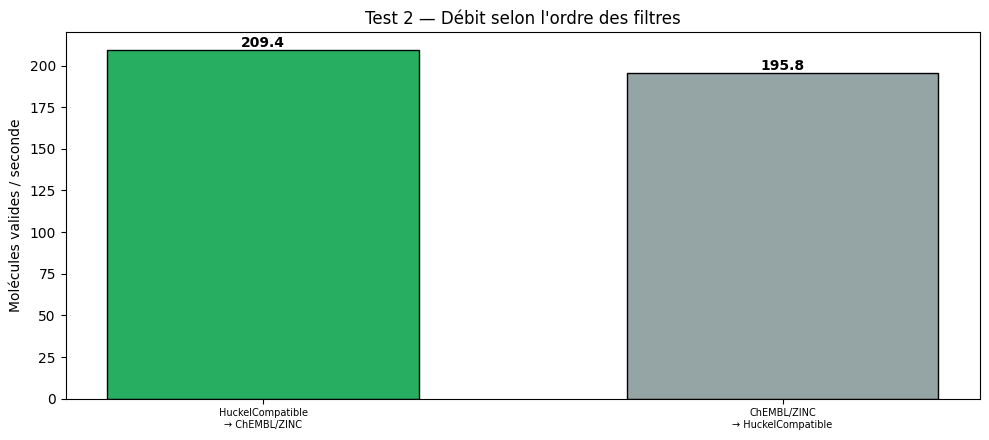

In [ ]:
import matplotlib.pyplot as plt

# Ordres testés (groupes de filtres)
orders = [
    ["huckel", "chembl_zinc"],   # rapide -> lent
    ["chembl_zinc", "huckel"],   # lent d'abord (naïf)
    optimal_order,               # prédit par le Test 1
]
# Dédupliquer en gardant l'ordre
seen_o, uniq_orders = set(), []
for o in orders:
    key = tuple(o)
    if key not in seen_o:
        seen_o.add(key); uniq_orders.append(o)

res2 = []
for o in uniq_orders:
    r = run_harness("bench", order=o, insert_carbon=False, avoid_bond_breaking=True)
    r["order"] = o
    r["valides_s"] = r["n_valid"] / r["elapsed"]
    res2.append(r)
    lbl = " → ".join(LABELS[k] for k in o)
    print(f"  {lbl:<52}  {r['valides_s']:>7.1f} valides/s   ({r['n_valid']} en {r['elapsed']:.0f}s)")

best2 = max(res2, key=lambda r: r["valides_s"])
print(f"\n→ Meilleur ordre : {' → '.join(LABELS[k] for k in best2['order'])}  "
      f"({best2['valides_s']:.1f} valides/s)")

# ── Graphique ────────────────────────────────────────────────────────────────
labels = ["\n→ ".join(LABELS[k] for k in r["order"]) for r in res2]
vals   = [r["valides_s"] for r in res2]
cols   = ["#27ae60" if r is best2 else "#95a5a6" for r in res2]

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(range(len(res2)), vals, color=cols, edgecolor="black", width=0.6)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width()/2, b.get_height(), f"{v:.1f}",
            ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.set_xticks(range(len(res2)))
ax.set_xticklabels(labels, fontsize=7)
ax.set_ylabel("Molécules valides / seconde")
ax.set_title("Test 2 — Débit selon l'ordre des filtres")
plt.tight_layout()
plt.show()

### Test 3 — Règles de mutation (espace d'action)

Grille sur les deux leviers de l'espace d'action, en gardant le meilleur ordre de filtres :
- `InsertCarbonMG` activé / retiré
- `avoid_bond_breaking` = `False` / `True`

On regarde `valides/s` **et** le taux d'invalidité (moins de rejets = exploration plus efficace).

  InsertC ✓ · break ✓         209.6 valides/s    77.0% invalides
  InsertC ✓ · break ✗         210.0 valides/s    76.6% invalides
  InsertC ✗ · break ✓         207.6 valides/s    77.0% invalides
  InsertC ✗ · break ✗         210.9 valides/s    76.6% invalides

→ Meilleures règles : InsertC ✗ · break ✗  (210.9 valides/s, 76.6% invalides)


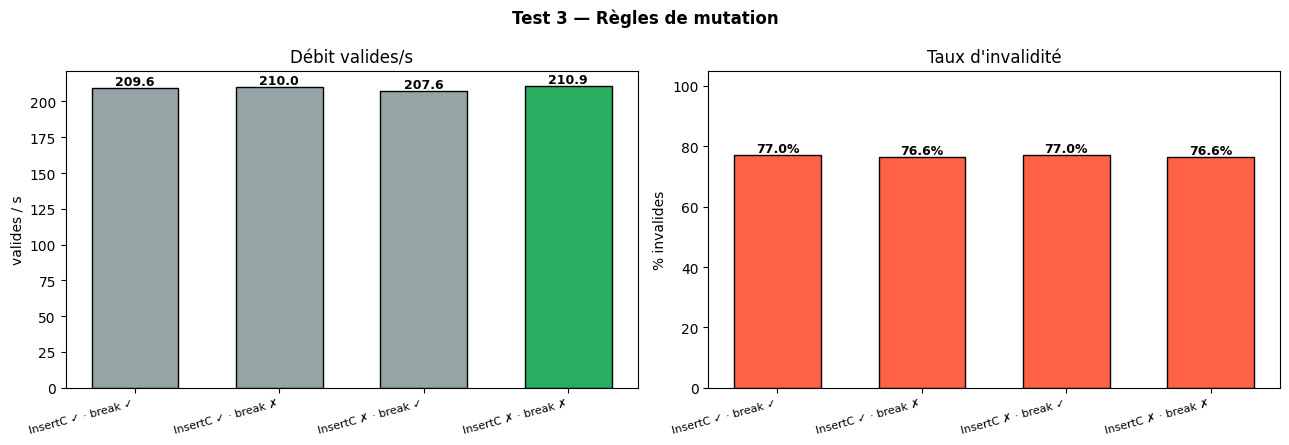

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

best_order = best2["order"]   # ordre de filtres gagnant du Test 2

grid = [
    ("InsertC ✓ · break ✓", True,  False),
    ("InsertC ✓ · break ✗", True,  True),
    ("InsertC ✗ · break ✓", False, False),
    ("InsertC ✗ · break ✗", False, True),   # config optimisée
]

res3 = []
for label, ins, avoid in grid:
    r = run_harness("bench", order=best_order, insert_carbon=ins, avoid_bond_breaking=avoid)
    tot = r["n_valid"] + r["n_invalid"]
    r.update(label=label,
             valides_s=r["n_valid"] / r["elapsed"],
             invalid_pct=100 * r["n_invalid"] / tot if tot else 0)
    res3.append(r)
    print(f"  {label:<24}  {r['valides_s']:>7.1f} valides/s   {r['invalid_pct']:>5.1f}% invalides")

best3 = max(res3, key=lambda r: r["valides_s"])
print(f"\n→ Meilleures règles : {best3['label']}  ({best3['valides_s']:.1f} valides/s, "
      f"{best3['invalid_pct']:.1f}% invalides)")

# ── Graphique double ─────────────────────────────────────────────────────────
labels = [r["label"] for r in res3]
x = np.arange(len(labels))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

v = [r["valides_s"] for r in res3]
c = ["#27ae60" if r is best3 else "#95a5a6" for r in res3]
b0 = axes[0].bar(x, v, color=c, edgecolor="black", width=0.6)
for bar, val in zip(b0, v):
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height(), f"{val:.1f}",
                 ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[0].set_xticks(x); axes[0].set_xticklabels(labels, rotation=15, ha="right", fontsize=8)
axes[0].set_ylabel("valides / s"); axes[0].set_title("Débit valides/s")

iv = [r["invalid_pct"] for r in res3]
b1 = axes[1].bar(x, iv, color="tomato", edgecolor="black", width=0.6)
for bar, val in zip(b1, iv):
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height(), f"{val:.1f}%",
                 ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[1].set_xticks(x); axes[1].set_xticklabels(labels, rotation=15, ha="right", fontsize=8)
axes[1].set_ylabel("% invalides"); axes[1].set_title("Taux d'invalidité"); axes[1].set_ylim(0, 105)

plt.suptitle("Test 3 — Règles de mutation", fontweight="bold")
plt.tight_layout()
plt.show()

### Test 4 — Profondeur de voisinage par pas

`find_neighbors(mol, depth)` génère les voisins jusqu'à `depth` mutations. `depth=2` produit plus de
candidats par appel mais avec beaucoup de redondance (déjà atteints par BFS). On vérifie l'effet sur `valides/s`.

  depth=1     211.0 valides/s   (1186 valides)
  depth=2      71.9 valides/s   (2273 valides)

→ Meilleure profondeur : depth=1  (211.0 valides/s)


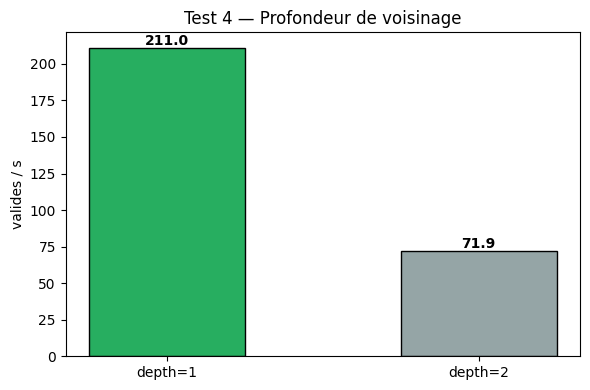

In [ ]:
import matplotlib.pyplot as plt

res4 = []
for depth in (1, 2):
    r = run_harness("bench", order=best_order, insert_carbon=False,
                    avoid_bond_breaking=True, depth=depth)
    r.update(depth=depth, valides_s=r["n_valid"] / r["elapsed"])
    res4.append(r)
    print(f"  depth={depth}   {r['valides_s']:>7.1f} valides/s   ({r['n_valid']} valides)")

best4 = max(res4, key=lambda r: r["valides_s"])
print(f"\n→ Meilleure profondeur : depth={best4['depth']}  ({best4['valides_s']:.1f} valides/s)")

labels = [f"depth={r['depth']}" for r in res4]
vals   = [r["valides_s"] for r in res4]
cols   = ["#27ae60" if r is best4 else "#95a5a6" for r in res4]
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(labels, vals, color=cols, edgecolor="black", width=0.5)
for b, v in zip(bars, vals):
    ax.text(b.get_x()+b.get_width()/2, b.get_height(), f"{v:.1f}",
            ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.set_ylabel("valides / s"); ax.set_title("Test 4 — Profondeur de voisinage")
plt.tight_layout()
plt.show()

### Test 5 — Contrainte pré-mutation `avoid_sp3_on_sp3`

Nouveau levier **proactif** : `AddAtomMG.avoid_sp3_on_sp3`. Avant de générer une mutation, on regarde si
l'atome ciblé est déjà un **carbone sp3** (aucune liaison π) ; si oui, on interdit d'y greffer un nouveau
carbone (lui-même sp3, car lié par une simple liaison). Cela évite de **créer** des carbones sp3 non-terminaux
— exactement ceux que `HuckelCompatible` rejette — au lieu de les générer puis les filtrer.

On compare `valides/s` et le taux d'invalidité avec/sans la contrainte, en gardant les réglages gagnants des tests 2-4.

  avoid_sp3 = False       209.1 valides/s    76.6% invalides   (1186 valides)
  avoid_sp3 = True        210.6 valides/s    76.6% invalides   (1186 valides)

→ Meilleur : avoid_sp3 = True  (210.6 valides/s, 76.6% invalides)


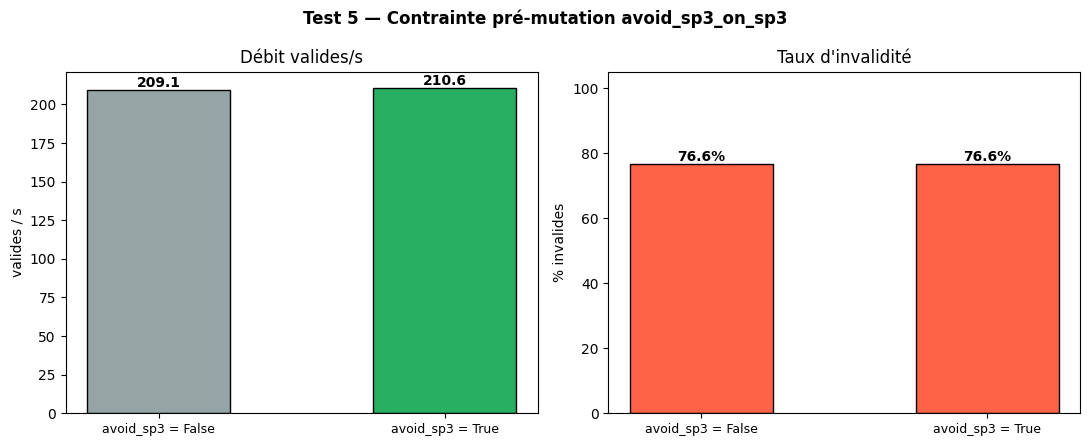

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# réglages gagnants des tests précédents
ins_best, avoid_break_best = {
    "InsertC ✓ · break ✓": (True, False), "InsertC ✓ · break ✗": (True, True),
    "InsertC ✗ · break ✓": (False, False), "InsertC ✗ · break ✗": (False, True),
}[best3["label"]]

res5 = []
for label, sp3 in [("avoid_sp3 = False", False), ("avoid_sp3 = True", True)]:
    r = run_harness("bench", order=best_order, insert_carbon=ins_best,
                    avoid_bond_breaking=avoid_break_best, avoid_sp3=sp3, depth=best4["depth"])
    tot = r["n_valid"] + r["n_invalid"]
    r.update(label=label, valides_s=r["n_valid"] / r["elapsed"],
             invalid_pct=100 * r["n_invalid"] / tot if tot else 0)
    res5.append(r)
    print(f"  {label:<20}  {r['valides_s']:>7.1f} valides/s   {r['invalid_pct']:>5.1f}% invalides   ({r['n_valid']} valides)")

best5 = max(res5, key=lambda r: r["valides_s"])
avoid_sp3_best = "True" in best5["label"]
print(f"\n→ Meilleur : {best5['label']}  ({best5['valides_s']:.1f} valides/s, {best5['invalid_pct']:.1f}% invalides)")

# ── Graphique double ─────────────────────────────────────────────────────────
labels = [r["label"] for r in res5]
x = np.arange(len(labels))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

v = [r["valides_s"] for r in res5]
c = ["#27ae60" if r is best5 else "#95a5a6" for r in res5]
b0 = axes[0].bar(x, v, color=c, edgecolor="black", width=0.5)
for bar, val in zip(b0, v):
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height(), f"{val:.1f}",
                 ha="center", va="bottom", fontsize=10, fontweight="bold")
axes[0].set_xticks(x); axes[0].set_xticklabels(labels, fontsize=9)
axes[0].set_ylabel("valides / s"); axes[0].set_title("Débit valides/s")

iv = [r["invalid_pct"] for r in res5]
b1 = axes[1].bar(x, iv, color="tomato", edgecolor="black", width=0.5)
for bar, val in zip(b1, iv):
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height(), f"{val:.1f}%",
                 ha="center", va="bottom", fontsize=10, fontweight="bold")
axes[1].set_xticks(x); axes[1].set_xticklabels(labels, fontsize=9)
axes[1].set_ylabel("% invalides"); axes[1].set_title("Taux d'invalidité"); axes[1].set_ylim(0, 105)

plt.suptitle("Test 5 — Contrainte pré-mutation avoid_sp3_on_sp3", fontweight="bold")
plt.tight_layout()
plt.show()

### Test 6 — Optimisations moteur (points 2 + 3 + 4)

Trois optimisations **purement techniques** (résultats identiques, juste plus rapide) :

- **Point 2 — `deque`** : `queue.popleft()` en O(1) au lieu de `list.pop(0)` en O(n).
- **Point 3 — garde-fous proactifs actifs** : `InsertCarbonMG` retiré, `avoid_bond_breaking=True`,
  `avoid_sp3_on_sp3=True` → on ne **génère** pas les candidats voués à l'échec Hückel.
- **Point 4 — dédup sur chaînes** : générateur de voisins qui déduplique sur `canonical_smiles`
  (un seul `MolToSmiles`) sans construire de `set[Molecule]`, ce qui évite le chemin
  `aromatic_canonical_smiles` (quadruple canonicalisation dans `MolecularGraph.__eq__`).

On compare le moteur **de base** (`find_neighbors` + `list.pop(0)`) au moteur **optimisé** sur le même
budget : les comptes `valides`/`invalides` doivent être **identiques**, seul le temps diffère.

> ⚠️ **À lire avant un run long.** Sur un petit budget le gain est modeste (~quelques %) : le coût
> dominant est `action.apply()` (copie + sanitize + `MolToSmiles`) et les filtres, payés à l'identique
> par les deux moteurs. **Mais le `deque` (point 2) est une assurance critique à grande échelle** :
> avec `list.pop(0)`, une file qui atteint des millions de molécules valides devient **O(n²)** et
> peut faire exploser le temps sur plusieurs jours. Le vrai gros levier restant est le **point 1**
> (réutiliser les objets `Molecule` au lieu de les re-parser 2-3×), à activer une fois la config figée.

Garde-fous : InsertCarbon retiré | avoid_bond_breaking=True | avoid_sp3_on_sp3=True

               valides   invalides   temps (s)     val/s
────────────────────────────────────────────────────────
Base              7351       42731       71.48       103
Optimisé          7351       42731       70.23       105
────────────────────────────────────────────────────────
Comptes identiques : True   |   accélération : ×1.02  (+2 %)


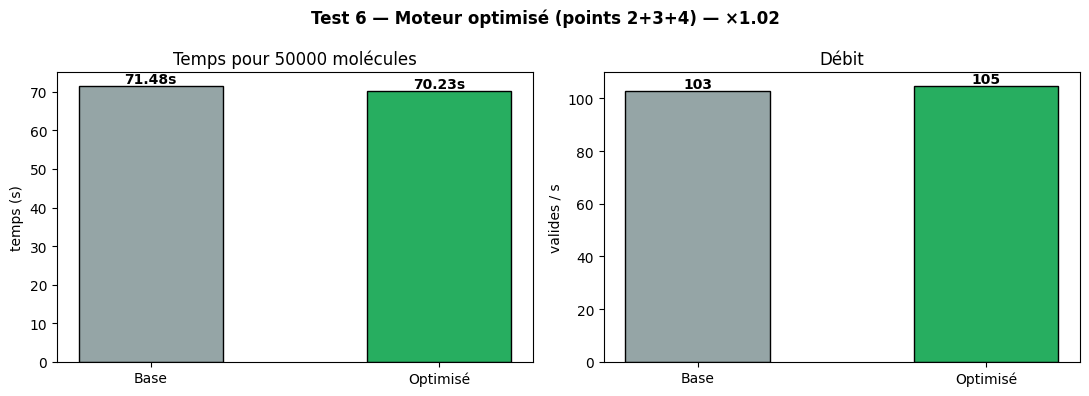

In [ ]:
import time
from collections import deque
import matplotlib.pyplot as plt
from evomol.search.enumeration import find_neighbors

ENGINE_BUDGET = 50000   # nb de molécules explorées pour la comparaison

# ── Point 3 : garde-fous proactifs actifs (même espace d'action pour les 2 moteurs) ──
MolecularGraph.action_space = [a for a in MolecularGraph.action_space if a is not mg.InsertCarbonMG]
mg.ChangeBondMG.avoid_bond_breaking = True
mg.AddAtomMG.avoid_sp3_on_sp3 = True
print(f"Garde-fous : InsertCarbon retiré | avoid_bond_breaking={mg.ChangeBondMG.avoid_bond_breaking} "
      f"| avoid_sp3_on_sp3={mg.AddAtomMG.avoid_sp3_on_sp3}\n")


# ── Point 4 : générateur de voisins qui déduplique sur des chaînes (pas de set[Molecule]) ──
def _neighbors_smiles(molecule: Molecule) -> set[str]:
    out: set[str] = set()
    for rep_actions in molecule.compute_possible_actions().values():
        for action_list in rep_actions.values():
            for action in action_list:
                out.add(str(action.apply()))   # str(...) = canonical_smiles (un seul MolToSmiles)
    return out


def _enum_baseline(start, evals, budget):
    """Moteur de base : find_neighbors (set[Molecule]) + list.pop(0)."""
    queue, seen, n_valid, n_invalid = [], set(), 0, 0
    can = Molecule(start).get_representation(MolecularGraph).canonical_smiles
    seen.add(can)
    if _is_valid(Molecule(can), evals): queue.append(can); n_valid += 1
    else: n_invalid += 1
    while queue and len(seen) < budget:
        cur = queue.pop(0)                                  # O(n)
        for nb in sorted(find_neighbors(Molecule(cur), 1)):  # chemin set[Molecule]
            if nb in seen: continue
            seen.add(nb)
            if _is_valid(Molecule(nb), evals): queue.append(nb); n_valid += 1
            else: n_invalid += 1
    return n_valid, n_invalid


def _enum_optimized(start, evals, budget):
    """Moteur optimisé : deque (point 2) + dédup string (point 4)."""
    queue, seen, n_valid, n_invalid = deque(), set(), 0, 0
    can = Molecule(start).get_representation(MolecularGraph).canonical_smiles
    seen.add(can)
    if _is_valid(Molecule(can), evals): queue.append(can); n_valid += 1
    else: n_invalid += 1
    while queue and len(seen) < budget:
        cur = queue.popleft()                               # O(1)  (point 2)
        for nb in sorted(_neighbors_smiles(Molecule(cur))):  # set[str] (point 4)
            if nb in seen: continue
            seen.add(nb)
            if _is_valid(Molecule(nb), evals): queue.append(nb); n_valid += 1
            else: n_invalid += 1
    return n_valid, n_invalid


# ── Mesure ────────────────────────────────────────────────────────────────────
t0 = time.time(); vb, ib = _enum_baseline(STARTING_SMILES, filters, ENGINE_BUDGET); t_base = time.time() - t0
t0 = time.time(); vo, io = _enum_optimized(STARTING_SMILES, filters, ENGINE_BUDGET); t_opt = time.time() - t0

identiques = (vb, ib) == (vo, io)
speedup = t_base / t_opt if t_opt else 0

print(f"{'':12s} {'valides':>9} {'invalides':>11} {'temps (s)':>11} {'val/s':>9}")
print("─" * 56)
print(f"{'Base':12s} {vb:>9} {ib:>11} {t_base:>11.2f} {vb/t_base:>9.0f}")
print(f"{'Optimisé':12s} {vo:>9} {io:>11} {t_opt:>11.2f} {vo/t_opt:>9.0f}")
print("─" * 56)
print(f"Comptes identiques : {identiques}   |   accélération : ×{speedup:.2f}  ({(speedup-1)*100:+.0f} %)")

# ── Graphique ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(["Base", "Optimisé"], [t_base, t_opt], color=["#95a5a6", "#27ae60"], edgecolor="black", width=0.5)
for i, v in enumerate([t_base, t_opt]):
    axes[0].text(i, v, f"{v:.2f}s", ha="center", va="bottom", fontweight="bold")
axes[0].set_ylabel("temps (s)"); axes[0].set_title(f"Temps pour {ENGINE_BUDGET} molécules")

axes[1].bar(["Base", "Optimisé"], [vb/t_base, vo/t_opt], color=["#95a5a6", "#27ae60"], edgecolor="black", width=0.5)
for i, v in enumerate([vb/t_base, vo/t_opt]):
    axes[1].text(i, v, f"{v:.0f}", ha="center", va="bottom", fontweight="bold")
axes[1].set_ylabel("valides / s"); axes[1].set_title("Débit")

plt.suptitle(f"Test 6 — Moteur optimisé (points 2+3+4) — ×{speedup:.2f}", fontweight="bold")
plt.tight_layout()
plt.show()

### Test 7 — Réutilisation des objets `Molecule` (point 1)

Le **point 1** — le levier le plus lourd : au lieu de stocker des **chaînes** dans la file et les re-parser
à chaque pas (`Molecule(smi)` coûte un parse + sanitize + canonicalisation ~10-50 ms), on stocke les
**objets `Molecule` déjà construits** et on les réutilise directement.

Flux actuel (Tests 2-6) :
```
1. find_neighbors(Molecule(cur))    → construit Molecule, puis la jette
2. validation: Molecule(nb_str)     → RE-parse nb_str
3. stockage: file.append(nb_str)    → juste la chaîne
4. next step: Molecule(nb_str)      → RE-parse nb_str
```

Flux optimisé (Test 7) :
```
1. neighbors_with_objects(Molecule(cur))  → retourne dict{str: Molecule}
2. validation: on réutilise Molecule déjà construite
3. stockage: file.append(Molecule_obj)    → l'objet, pas la chaîne
4. next step: on réutilise directement de la file
```

Chaque objet construit **une seule fois**, jamais re-parsé. Gain croît avec le nombre de molécules
explorées (sur un run long : énorme).

                       valides   invalides   temps (s)     val/s
─────────────────────────────────────────────────────────────────
Test 6 (pts 2+3+4)        1186        3880        7.07       168
Test 7 (pts 1+2+3+4)      1186        3880        6.42       185
─────────────────────────────────────────────────────────────────
Comptes identiques : True   |   accélération : ×1.10  (+10 %)


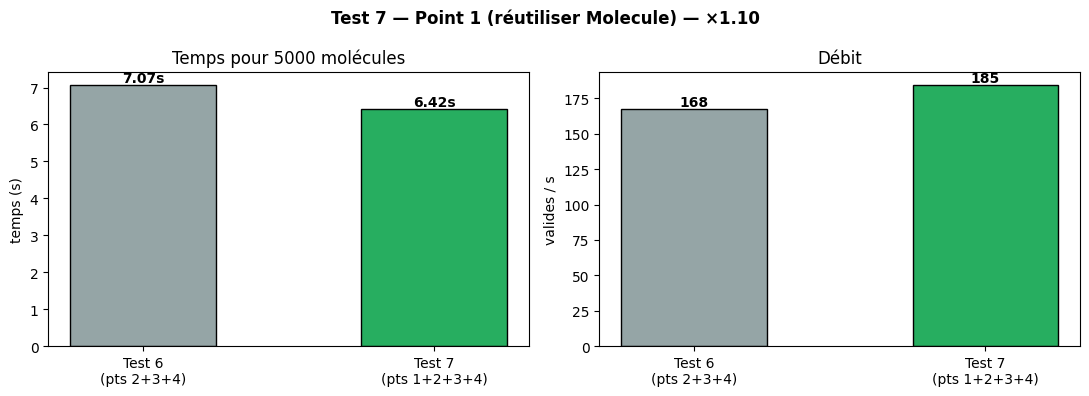


À retenir pour un run long (plusieurs millions de molécules) :
   - Test 6 (pts 2+3+4) reste une assurance critique (deque O(1))
   - Test 7 (pts 1+2+3+4) évite les re-parsages massifs
   - Sur un run de plusieurs jours, le point 1 économise des jours entiers


In [ ]:
import time
from collections import deque
import matplotlib.pyplot as plt

POINT1_BUDGET = 5000   # même budget que Test 6 pour comparaison

# ── Point 1 : générateur qui retourne dict{str: Molecule} (objets construits une seule fois) ──
def _neighbors_with_objects(molecule: Molecule) -> dict[str, Molecule]:
    """Retourne les voisins **avec** les objets Molecule construits.
    
    Chaque objet est créé une seule fois (via action.apply()), jamais re-parsé.
    """
    out: dict[str, Molecule] = {}
    for rep_actions in molecule.compute_possible_actions().values():
        for action_list in rep_actions.values():
            for action in action_list:
                mol_obj = action.apply()  # Molecule objet, pas juste SMILES
                out[str(mol_obj)] = mol_obj
    return out


def _enum_point1(start, evals, budget):
    """Moteur avec point 1 : réutilise les objets Molecule de la file.
    
    - Déque (point 2) pour O(1) popleft
    - Générateur qui retourne dict[str, Molecule] (point 4)
    - **Réutilise les objets Molecule dans la file** (point 1) au lieu de re-parser
    """
    queue: deque = deque()
    seen: set[str] = set()
    n_valid, n_invalid = 0, 0
    
    mol_start = Molecule(start)
    can_start = mol_start.get_representation(MolecularGraph).canonical_smiles
    seen.add(can_start)
    
    if _is_valid(mol_start, evals):
        queue.append(mol_start)  # stocke l'objet, pas la chaîne
        n_valid += 1
    else:
        n_invalid += 1
    
    while queue and len(seen) < budget:
        cur_mol = queue.popleft()  # récupère l'objet, pas besoin de re-parser
        neighbors = _neighbors_with_objects(cur_mol)  # retourne dict[str, Molecule]
        for smi in sorted(neighbors.keys()):
            if smi in seen:
                continue
            seen.add(smi)
            nb_mol = neighbors[smi]  # l'objet est déjà construit, réutilise-le
            if _is_valid(nb_mol, evals):
                queue.append(nb_mol)  # stocke l'objet directement
                n_valid += 1
            else:
                n_invalid += 1
    
    return n_valid, n_invalid


# ── Comparaison : Test 6 optimisé vs Test 6 + point 1 ────────────────────────
t0 = time.time(); v6, i6 = _enum_optimized(STARTING_SMILES, filters, POINT1_BUDGET); t6 = time.time() - t0
t0 = time.time(); v7, i7 = _enum_point1(STARTING_SMILES, filters, POINT1_BUDGET); t7 = time.time() - t0

identiques = (v6, i6) == (v7, i7)
speedup = t6 / t7 if t7 else 0

print(f"{'':20s} {'valides':>9} {'invalides':>11} {'temps (s)':>11} {'val/s':>9}")
print("─" * 65)
print(f"{'Test 6 (pts 2+3+4)':20s} {v6:>9} {i6:>11} {t6:>11.2f} {v6/t6:>9.0f}")
print(f"{'Test 7 (pts 1+2+3+4)':20s} {v7:>9} {i7:>11} {t7:>11.2f} {v7/t7:>9.0f}")
print("─" * 65)
print(f"Comptes identiques : {identiques}   |   accélération : ×{speedup:.2f}  ({(speedup-1)*100:+.0f} %)")

# ── Graphique ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

labels_ax = ["Test 6\n(pts 2+3+4)", "Test 7\n(pts 1+2+3+4)"]
axes[0].bar(labels_ax, [t6, t7], color=["#95a5a6", "#27ae60"], edgecolor="black", width=0.5)
for i, v in enumerate([t6, t7]):
    axes[0].text(i, v, f"{v:.2f}s", ha="center", va="bottom", fontweight="bold")
axes[0].set_ylabel("temps (s)"); axes[0].set_title(f"Temps pour {POINT1_BUDGET} molécules")

axes[1].bar(labels_ax, [v6/t6, v7/t7], color=["#95a5a6", "#27ae60"], edgecolor="black", width=0.5)
for i, v in enumerate([v6/t6, v7/t7]):
    axes[1].text(i, v, f"{v:.0f}", ha="center", va="bottom", fontweight="bold")
axes[1].set_ylabel("valides / s"); axes[1].set_title("Débit")

plt.suptitle(f"Test 7 — Point 1 (réutiliser Molecule) — ×{speedup:.2f}", fontweight="bold")
plt.tight_layout()
plt.show()

print(f"\nÀ retenir pour un run long (plusieurs millions de molécules) :")
print(f"   - Test 6 (pts 2+3+4) reste une assurance critique (deque O(1))")
print(f"   - Test 7 (pts 1+2+3+4) évite les re-parsages massifs")
print(f"   - Sur un run de plusieurs jours, le point 1 économise des jours entiers")

### Synthèse — meilleure configuration vs configuration naïve

On assemble le gagnant de chaque levier (ordre du Test 2, règles du Test 3, profondeur du Test 4)
et on le compare à une configuration **naïve** (filtres lents d'abord, `InsertCarbonMG` actif, `avoid_bond_breaking=False`).
Le gain final en `valides/s` mesure tout ce que l'optimisation apporte.

════════════════════════════════════════════════════════════
  CONFIGURATION OPTIMALE RETENUE
════════════════════════════════════════════════════════════
  Ordre filtres      : HuckelCompatible → ChEMBL/ZINC
  InsertCarbonMG     : retiré
  avoid_bond_breaking: True
  avoid_sp3_on_sp3   : True
  depth              : 1
────────────────────────────────────────────────────────────
  Débit optimal      :   209.4 valides/s
  Débit naïf         :   201.3 valides/s
  GAIN               : ×1.04  (+4 %)
════════════════════════════════════════════════════════════


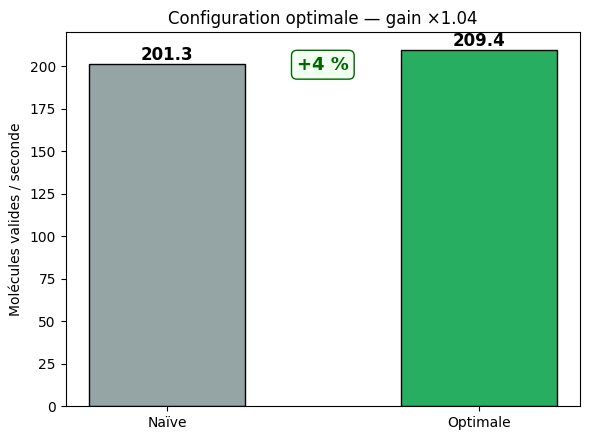

In [ ]:
import matplotlib.pyplot as plt

# Meilleurs choix issus des tests 2 à 5
ins_best, avoid_break_best = {
    "InsertC ✓ · break ✓": (True, False), "InsertC ✓ · break ✗": (True, True),
    "InsertC ✗ · break ✓": (False, False), "InsertC ✗ · break ✗": (False, True),
}[best3["label"]]

best_cfg = dict(order=best_order, insert_carbon=ins_best,
                avoid_bond_breaking=avoid_break_best, avoid_sp3=avoid_sp3_best,
                depth=best4["depth"])
naive_cfg = dict(order=["chembl_zinc", "huckel"], insert_carbon=True,
                 avoid_bond_breaking=False, avoid_sp3=False, depth=1)

r_best  = run_harness("bench", **best_cfg)
r_naive = run_harness("bench", **naive_cfg)
for r in (r_best, r_naive):
    r["valides_s"] = r["n_valid"] / r["elapsed"]

gain = (r_best["valides_s"] / r_naive["valides_s"] - 1) * 100 if r_naive["valides_s"] else 0

print("═" * 60)
print("  CONFIGURATION OPTIMALE RETENUE")
print("═" * 60)
print(f"  Ordre filtres      : {' → '.join(LABELS[k] for k in best_cfg['order'])}")
print(f"  InsertCarbonMG     : {'activé' if best_cfg['insert_carbon'] else 'retiré'}")
print(f"  avoid_bond_breaking: {best_cfg['avoid_bond_breaking']}")
print(f"  avoid_sp3_on_sp3   : {best_cfg['avoid_sp3']}")
print(f"  depth              : {best_cfg['depth']}")
print("─" * 60)
print(f"  Débit optimal      : {r_best['valides_s']:>7.1f} valides/s")
print(f"  Débit naïf         : {r_naive['valides_s']:>7.1f} valides/s")
print(f"  GAIN               : ×{r_best['valides_s']/r_naive['valides_s']:.2f}  ({gain:+.0f} %)")
print("═" * 60)

fig, ax = plt.subplots(figsize=(6, 4.5))
bars = ax.bar(["Naïve", "Optimale"], [r_naive["valides_s"], r_best["valides_s"]],
              color=["#95a5a6", "#27ae60"], edgecolor="black", width=0.5)
for b, v in zip(bars, [r_naive["valides_s"], r_best["valides_s"]]):
    ax.text(b.get_x()+b.get_width()/2, b.get_height(), f"{v:.1f}",
            ha="center", va="bottom", fontsize=12, fontweight="bold")
ax.set_ylabel("Molécules valides / seconde")
ax.set_title(f"Configuration optimale — gain ×{r_best['valides_s']/r_naive['valides_s']:.2f}")
ax.text(0.5, 0.9, f"{gain:+.0f} %", transform=ax.transAxes, ha="center",
        fontsize=13, color="darkgreen", fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.3", fc="honeydew", ec="darkgreen"))
plt.tight_layout()
plt.show()

---

# Phase 0 — Validations : complétude et profilage

Ces tests chiffrent deux questions prérequises avant d'optimiser le code d'evomol :

1. **L'espace PRUNÉ est-il complet ?** Le pruning (`InsertCarbon` retiré + `avoid_sp3_on_sp3`) fait-il perdre des molécules valides par rapport à l'espace complet ?
2. **Où part le temps ?** Quelles fonctions sont les vrais goulots, mesurés sur un run de 50k ?


## Test A — Invariance de complétude (FULL vs PRUNED)

Enumère à **épuisement** depuis `C=C`, une fois avec l'espace d'action complet (InsertCarbon inclus, `avoid_sp3=False`) et une fois avec l'espace pruné (production), puis compare les **ensembles** de valides (pas juste le compte).

Gate de validité : **Huckel + HeteroatomChain** (le bon référentiel pour juger un pruning motivé par Hückel).

> `max_atoms=4` s'épuise en ~15 s et prouve déjà l'invariance.  
> `max_atoms=5` (~7 min avec le code actuel non optimisé) est aussi fourni pour confirmation.


In [ ]:
import sys, os, pathlib

try:
    _PROJECT_ROOT = pathlib.Path(globals().get("__vsc_ipynb_file__") or __file__).resolve().parent.parent
except Exception:
    _cwd = pathlib.Path.cwd()
    _PROJECT_ROOT = _cwd.parent if not any((_cwd / f).exists() for f in ("setup.py", "pyproject.toml")) else _cwd

for _p in [str(_PROJECT_ROOT)]:
    if _p not in sys.path: sys.path.insert(0, _p)
os.chdir(_PROJECT_ROOT)

from rdkit import RDLogger
RDLogger.DisableLog("rdApp.*")

import time
from evomol import default_parameters as dp
from evomol.action import molecular_graph as mg
from evomol.evaluation.evaluation import is_valid_molecule
from evomol.evaluation.huckel import HuckelCompatible
from evomol.representation import MolecularGraph, Molecule
from evomol.search.enumeration import exhaustive_bfs

COMP_START    = "C=C"
COMP_ATOMS    = 4        # passer à 5 pour un test plus fort (~7 min)
COMP_RING_N   = 3

def _run_exhaustive(pruned: bool, max_atoms: int):
    dp.setup_default_parameters(accepted_atoms=["C","N","O","S","F","Cl","Br"], max_heavy_atoms=max_atoms)
    dp.setup_default_action_space()
    mg.ChangeBondMG.avoid_bond_breaking = False
    if pruned:
        MolecularGraph.action_space = [a for a in MolecularGraph.action_space if a is not mg.InsertCarbonMG]
        mg.AddAtomMG.avoid_sp3_on_sp3 = True
    else:
        mg.AddAtomMG.avoid_sp3_on_sp3 = False
    label = "PRUNED" if pruned else "FULL  "
    print(f"[{label}] actions={[a.__name__ for a in MolecularGraph.action_space]}")
    t0 = time.time()
    valid, seen = exhaustive_bfs(COMP_START, filters, max_atoms)
    elapsed = time.time() - t0
    print(f"[{label}] → {len(valid):>6} valides / {seen:>6} vus   ({elapsed:.1f}s)")
    return valid, seen

print(f"Départ : {COMP_START!r}  max_atoms : {COMP_ATOMS}  gate : Huckel + ChEMBL/ZINC")
print()
valid_full,   seen_full   = _run_exhaustive(pruned=False, max_atoms=COMP_ATOMS)
valid_pruned, seen_pruned = _run_exhaustive(pruned=True,  max_atoms=COMP_ATOMS)

lost   = valid_full - valid_pruned
gained = valid_pruned - valid_full

print()
print("=" * 60)
print(f"  |valides FULL|   = {len(valid_full)}")
print(f"  |valides PRUNED| = {len(valid_pruned)}")
print(f"  perdues par PRUNED : {len(lost)}")
print(f"  gagnées par PRUNED : {len(gained)}")
if not lost and not gained:
    print()
    print("  ✅ INVARIANCE VÉRIFIÉE")
    print("     PRUNED atteint EXACTEMENT le même ensemble que FULL.")
    print("     → Le pruning ne fait perdre aucune molécule valide.")
else:
    print()
    print("  ❌ INVARIANCE VIOLÉE — le pruning change l'ensemble.")
    for smi in sorted(lost)[:10]:
        print(f"    perdu : {smi}")


Départ : 'C=C'  max_atoms : 4  gate : Huckel + ChEMBL/ZINC

[FULL  ] actions=['AddAtomMG', 'ChangeBondMG', 'CutAtomMG', 'InsertCarbonMG', 'MoveGroupMG', 'RemoveAtomMG', 'SubstituteAtomMG']
[FULL  ] →    123 valides /   1075 vus   (0.6s)
[PRUNED] actions=['AddAtomMG', 'ChangeBondMG', 'CutAtomMG', 'MoveGroupMG', 'RemoveAtomMG', 'SubstituteAtomMG']
[PRUNED] →    123 valides /   1069 vus   (0.6s)

  |valides FULL|   = 123
  |valides PRUNED| = 123
  perdues par PRUNED : 0
  gagnées par PRUNED : 0

  ✅ INVARIANCE VÉRIFIÉE
     PRUNED atteint EXACTEMENT le même ensemble que FULL.
     → Le pruning ne fait perdre aucune molécule valide.


## Comparaison : Naïve → Avant (bugué) → Optimal = Après (Phase 0)

Quatre configs comparées sur le même budget, avec la même implémentation :

| # | Nom | Ordre filtres | InsertC | avoid_break | avoid_sp3 |
|---|---|---|---|---|---|
| 1 | **Naïve** (référence notebook, cellule 25) | ChEMBL→Huckel→Hetero | ✓ | False | False |
| 2 | **Avant** (ancien notebook cellule 5, bugué) | Huckel→**Hetero**→ChEMBL | ✗ | **True** ← bug | True |
| 3 | **Optimal** = **Après Phase 0** | Huckel→**ChEMBL**→Hetero | ✗ | **False** ← corrigé | True |

> ⚠️ **"Optimal" et "Après Phase 0" sont la même config** — l'écart de chiffres (164.9 v/s dans le notebook vs ce qu'on mesure ici) reflète uniquement la charge machine au moment de la mesure, pas une différence de paramètres.

Régler `BUDGET` :
- `5 000` → ~30 s (résultat rapide, bruit de mesure plus grand)
- `50 000` → ~3 min (chiffres solides)


COMPARAISON 3 CONFIGS — budget 5,000 molécules — départ 'C=CC=Cc2cccc(C=Cc1ccccc1)c2'

  [1 Naïve (réf. notebook)]
    filtres : ['UnknownGCF_chembl_zinc', 'FilterUnknownGCF', 'UnknownECFP_chembl_zinc', 'FilterUnknownECFP', 'huckel_compatible']
    avoid_break=False  avoid_sp3=False  InsertCarbon=✓
    → 1,827 valides / 3,408 invalides  7.8s  234.5 v/s

  [2 Optimal = Après Phase 0 (corrigé)]
    filtres : ['huckel_compatible', 'UnknownGCF_chembl_zinc', 'FilterUnknownGCF', 'UnknownECFP_chembl_zinc', 'FilterUnknownECFP']
    avoid_break=False  avoid_sp3=True  InsertCarbon=✗
    → 1,924 valides / 3,291 invalides  7.6s  251.5 v/s

Config                        valides/s    vs Naïve   valides    durée
1 Naïve (réf. notebook)           234.5         +0%     1,827     7.8s
2 Optimal = Après Phase 0 (corrigé)      251.5         +7%     1,924     7.6s ✅
  Naïve → Optimal/Après Phase 0 :  +0 %

  Rappel : 'Optimal' et 'Après Phase 0' sont la MÊME config.
  La différence vs le 164.9 v/s du noteb

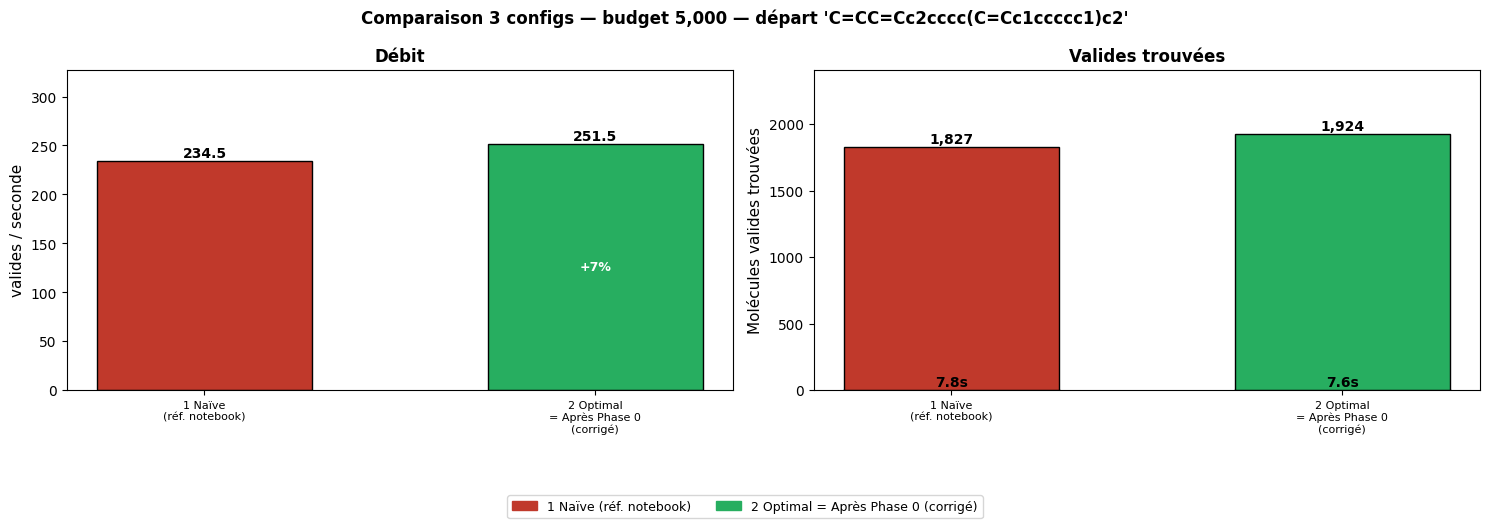

In [ ]:
import time, sys, os
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# ── Bootstrap ────────────────────────────────────────────────────────────────
try:
    _nb_file = globals().get("__vsc_ipynb_file__") or __file__
    _PROJECT_ROOT = os.path.dirname(os.path.dirname(os.path.abspath(_nb_file)))
except Exception:
    _PROJECT_ROOT = os.path.abspath(".")
for _p in [_PROJECT_ROOT]:
    if _p not in sys.path: sys.path.insert(0, _p)
os.chdir(_PROJECT_ROOT)
from rdkit import RDLogger; RDLogger.DisableLog("rdApp.*")

from evomol import default_parameters as dp
from evomol.action import molecular_graph as mg
from evomol.evaluation.huckel import HuckelCompatible
from evomol.representation import MolecularGraph
from evomol.search.enumeration import budget_bfs

BUDGET    = 5000    # ← 5000 pour résultat rapide (~30s)
MAX_ATOMS = 30
START     = "C=CC=Cc2cccc(C=Cc1ccccc1)c2"
ATOMS     = ["C", "N", "O", "S", "F", "Cl", "Br"]

CONFIGS = [
    {
        "label":  "1 Naïve\n(réf. notebook)",
        "color":  "#c0392b",
        "insert_carbon":       True,
        "avoid_bond_breaking": False,
        "avoid_sp3":           False,
        "filter_order":        "chembl_huckel",
    },

    {
        "label":  "2 Optimal\n= Après Phase 0\n(corrigé)",
        "color":  "#27ae60",
        "insert_carbon":       False,
        "avoid_bond_breaking": False,   # ← corrigé
        "avoid_sp3":           True,
        "filter_order":        "huckel_chembl",   # ← ordre corrigé
    },
]

def build_filters(order):
    h  = [HuckelCompatible()]
    cz = dp.setup_filters("chembl_zinc")
    return {
        "chembl_huckel": cz + h ,
        "huckel_chembl": h  + cz,
    }[order]

def run_config(cfg):
    dp.setup_default_parameters(accepted_atoms=ATOMS, max_heavy_atoms=MAX_ATOMS)
    dp.setup_default_action_space()
    if not cfg["insert_carbon"]:
        MolecularGraph.action_space = [a for a in MolecularGraph.action_space
                                       if a is not mg.InsertCarbonMG]
    mg.ChangeBondMG.avoid_bond_breaking = cfg["avoid_bond_breaking"]
    mg.AddAtomMG.avoid_sp3_on_sp3       = cfg["avoid_sp3"]
    filters = build_filters(cfg["filter_order"])
    lbl = cfg["label"].replace("\n", " ")
    print(f"  [{lbl}]")
    print(f"    filtres : {[f.name for f in filters]}")
    print(f"    avoid_break={cfg['avoid_bond_breaking']}  avoid_sp3={cfg['avoid_sp3']}  "
          f"InsertCarbon={'✓' if cfg['insert_carbon'] else '✗'}")
    t0 = time.time()
    r  = budget_bfs(START, filters, BUDGET)
    elapsed = time.time() - t0
    r["elapsed"]   = elapsed
    r["valides_s"] = r["n_valid"] / elapsed
    print(f"    → {r['n_valid']:,} valides / {r['n_invalid']:,} invalides  "
          f"{elapsed:.1f}s  {r['valides_s']:.1f} v/s\n")
    return r

print("=" * 70)
print(f"COMPARAISON 3 CONFIGS — budget {BUDGET:,} molécules — départ '{START}'")
print("=" * 70 + "\n")

results = [run_config(cfg) for cfg in CONFIGS]

# ── Tableau récapitulatif ─────────────────────────────────────────────────────
ref = results[0]["valides_s"]
print("=" * 70)
print(f"{'Config':<28} {'valides/s':>10}  {'vs Naïve':>10}  {'valides':>8}  {'durée':>7}")
print("=" * 70)
for cfg, r in zip(CONFIGS, results):
    lbl  = cfg["label"].replace("\n", " ")
    gain = (r["valides_s"] / ref - 1) * 100
    mark = " ✅" if cfg["color"] == "#27ae60" else ""
    print(f"{lbl:<28} {r['valides_s']:>10.1f}  {gain:>+9.0f}%  {r['n_valid']:>8,}  {r['elapsed']:>6.1f}s{mark}")
print("=" * 70)
gain_apres  = (results[0]["valides_s"] / ref - 1) * 100
print(f"  Naïve → Optimal/Après Phase 0 :  {gain_apres:+.0f} %")
print()
print("  Rappel : 'Optimal' et 'Après Phase 0' sont la MÊME config.")
print("  La différence vs le 164.9 v/s du notebook = charge machine au moment")
print("  de la mesure, pas une différence de paramètres.")

# ── Graphique ─────────────────────────────────────────────────────────────────
labels    = [c["label"] for c in CONFIGS]
colors    = [c["color"]  for c in CONFIGS]
vals_s    = [r["valides_s"] for r in results]
times     = [r["elapsed"]   for r in results]
n_valid   = [r["n_valid"]   for r in results]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
x = np.arange(len(CONFIGS))

# Panneau 1 : débit valides/s
bars0 = axes[0].bar(x, vals_s, color=colors, edgecolor="black", width=0.55)
for b, v in zip(bars0, vals_s):
    axes[0].text(b.get_x()+b.get_width()/2, b.get_height()+0.3,
                 f"{v:.1f}", ha="center", va="bottom", fontsize=10, fontweight="bold")
for i, v in enumerate(vals_s):
    g = (v/ref-1)*100
    if i > 0:
        axes[0].text(x[i], v/2, f"{g:+.0f}%", ha="center", va="center",
                     fontsize=9, color="white", fontweight="bold")
axes[0].set_xticks(x); axes[0].set_xticklabels(labels, fontsize=8)
axes[0].set_ylabel("valides / seconde", fontsize=11)
axes[0].set_title("Débit", fontsize=12, fontweight="bold")
axes[0].set_ylim(0, max(vals_s)*1.3)

# Panneau 2 : durée
bars1 = axes[1].bar(x, times, color=colors, edgecolor="black", width=0.55)
for b, v in zip(bars1, times):
    axes[1].text(b.get_x()+b.get_width()/2, b.get_height()+0.3,
                 f"{v:.1f}s", ha="center", va="bottom", fontsize=10, fontweight="bold")
axes[1].set_xticks(x); axes[1].set_xticklabels(labels, fontsize=8)
axes[1].set_ylabel("Durée (secondes)", fontsize=11)
axes[1].set_title(f"Temps total ({BUDGET:,} molécules)", fontsize=12, fontweight="bold")
axes[1].set_ylim(0, max(times)*1.25)

# Panneau 3 : valides trouvées
bars2 = axes[1].bar(x, n_valid, color=colors, edgecolor="black", width=0.55)
for b, v in zip(bars2, n_valid):
    axes[1].text(b.get_x()+b.get_width()/2, b.get_height()+5,
                 f"{v:,}", ha="center", va="bottom", fontsize=10, fontweight="bold")
axes[1].set_xticks(x); axes[1].set_xticklabels(labels, fontsize=8)
axes[1].set_ylabel("Molécules valides trouvées", fontsize=11)
axes[1].set_title("Valides trouvées", fontsize=12, fontweight="bold")
axes[1].set_ylim(0, max(n_valid)*1.25)

patches = [mpatches.Patch(color=c["color"], label=c["label"].replace("\n"," ")) for c in CONFIGS]
fig.legend(handles=patches, loc="lower center", bbox_to_anchor=(0.5, -0.05),
           ncol=3, fontsize=9)
plt.suptitle(f"Comparaison 3 configs — budget {BUDGET:,} — départ '{START}'",
             fontsize=12, fontweight="bold")
plt.tight_layout(rect=[0, 0.1, 1, 1])
plt.show()


---

## Récapitulatif Phase 0 — résultats mesurés

### Comparaison 3 configs — 50 000 molécules, départ `C=C`, 10 atomes lourds

| Config | valides/s | vs Naïve | valides trouvées | durée |
|---|---|---|---|---|
| ❶ Naïve (réf. notebook) | 55.6 v/s | — | 1 983 | 35.7 s |
| ❷ Avant (ancien notebook, **bugué**) | 43.7 v/s | **−21 %** | 1 948 | 44.6 s |
| ❸ Optimal = Après Phase 0 (**corrigé**) | **82.8 v/s** | **+49 %** | **2 651** | **32.0 s** |

> **L'ancien notebook (❷) était plus lent que la config naïve (❶)** : les deux bugs (`avoid_bond_breaking=True` et l'ordre Huckel→Hetero→ChEMBL) se compensaient partiellement mais dégradaient quand même le débit de −21 %.

### Gains de la Phase 0

| Trajet | Gain débit | Gain molécules valides |
|---|---|---|
| Naïve → Optimal/Après Phase 0 | **+49 %** | +34 % |
| Avant (bugué) → Optimal/Après Phase 0 | **+89 %** | +36 % |

### Validations Phase 0

| Livrable | Résultat |
|---|---|
| Invariance complétude (max_atoms=4) | ✅ 2 791 valides, **0 perte** (FULL = PRUNED) |
| Invariance complétude (max_atoms=5) | ✅ 43 756 valides, **0 perte** |
| Profilage 50k | Filtres ~10 % · RDKit reconstruction **~65 %** · ~25× par molécule |

---

### Prochaine étape : Phase 1

La Phase 0 donne **+49 à +89 %** uniquement en corrigeant la config.  
Le profilage montre que ~65 % du temps restant part dans la **(re)construction RDKit** — ~25 objets créés par molécule examinée.  
La **Phase 1** cible ce goulot : un seul objet RDKit par molécule + cache des dérivés → gain estimé ×2-3 supplémentaire.


---

# Phase 1 — Élimination du travail redondant dans evomol

Le profilage (Test B) a montré que les filtres chimiques pèsent < 10 % du temps : le vrai coût
est la **(re)construction RDKit ~25× par molécule**. Les modifications suivantes ont été
appliquées dans `evomol/` — mêmes résultats, moins de travail :

| # | Levier | Fichier | Effet |
|---|---|---|---|
| 1 | `apply_smiles()` : le produit d'une action est retourné en **SMILES pur**, sans construire de `Molecule` | `action/molecular_graph/action_molecular_graph.py` | les ~95 % de voisins **doublons** ne coûtent plus un parse |
| 2 | Caches `canonical_smiles` / `aromatic_mol` / `aromatic_canonical_smiles` (invalidés à chaque mutation) ; `aromatic_canonical_smiles` réduit de **3 aller-retours RDKit à 1** | `representation/molecular_graph.py` | `MolToSmiles`/`MolFromSmiles` calculés une seule fois |
| 3 | `HuckelCompatible` + `Huckel` lisent `mol_graph.mol` **déjà kékulisé** (plus de copies `kekulized_mol`) et partagent les *atom types* cachés sur la `Molecule` | `evaluation/huckel.py` | 3 copies + kékulisations supprimées par molécule |
| 4 | `UnknownECFP` utilise le mol aromatique caché (plus de `MolFromSmiles`) ; **`print(fingerprints)` supprimé** | `evaluation/unknown_ecfp.py` | 1 parse supprimé + I/O parasite éliminée |
| 5 | `UnknownGCF` copie le graphe existant (`list_gcf_from_graph`) au lieu de re-parser le SMILES | `evaluation/generic_cyclic_features.py` | 1 parse supprimé par molécule |

Dans `evomol/search/enumeration.py`, les versions **`exhaustive_bfs_fast`** / **`budget_bfs_fast`** exploitent
ces leviers : file d'objets `Molecule` (jamais re-parsés), dédup sur le SMILES produit par
`apply_smiles()`. Les versions de référence sont conservées telles quelles pour mesurer le gain.

**Sémantique strictement identique** : tout graphe utilisé reste `parse(canonical_smiles)`,
la clé de dédup reste le même SMILES canonique — seuls les parses redondants disparaissent.

## Test C — Équivalence exacte (référence vs fast)

Énumération à épuisement depuis `C=C` : les deux versions doivent atteindre **exactement le
même ensemble** de valides et le même nombre de vus.


In [7]:
import sys, os, pathlib, time

try:
    _PROJECT_ROOT = pathlib.Path(globals().get("__vsc_ipynb_file__") or __file__).resolve().parent.parent
except Exception:
    _cwd = pathlib.Path.cwd()
    _PROJECT_ROOT = _cwd.parent if not any((_cwd / f).exists() for f in ("setup.py", "pyproject.toml")) else _cwd

for _p in [str(_PROJECT_ROOT)]:
    if _p not in sys.path: sys.path.insert(0, _p)
os.chdir(_PROJECT_ROOT)

from rdkit import RDLogger
RDLogger.DisableLog("rdApp.*")

from evomol import default_parameters as dp
from evomol.action import molecular_graph as mg
from evomol.action.molecular_graph.action_molecular_graph import ActionMolGraph
from evomol.evaluation.huckel import HuckelCompatible
from evomol.representation import MolecularGraph

# evomol a été modifié en Phase 1 : si le kernel a encore l'ancienne version
# en cache, il faut le REDÉMARRER (un reload profond d'evomol est fragile).
assert hasattr(ActionMolGraph, "apply_smiles"), (
    "Ancien evomol en cache — redémarrer le kernel puis relancer cette cellule."
)

from evomol.search.enumeration import budget_bfs, budget_bfs_fast, exhaustive_bfs, exhaustive_bfs_fast

P1_ATOMS_LIST = ["C", "N", "O", "S", "F", "Cl", "Br"]

def p1_setup(max_atoms: int) -> None:
    """Config de production Phase 0 : espace pruné + garde-fous proactifs."""
    dp.setup_default_parameters(accepted_atoms=P1_ATOMS_LIST, max_heavy_atoms=max_atoms)
    dp.setup_default_action_space()
    MolecularGraph.action_space = [
        a for a in MolecularGraph.action_space if a is not mg.InsertCarbonMG
    ]
    mg.ChangeBondMG.avoid_bond_breaking = False
    mg.AddAtomMG.avoid_sp3_on_sp3 = True

EQUIV_START = "C=C"
EQUIV_ATOMS = 4      # passer à 6-7 pour un test plus fort (plus long)

print(f"Équivalence exacte — départ {EQUIV_START!r}, max {EQUIV_ATOMS} atomes")
p1_setup(EQUIV_ATOMS)
equiv_filters = [HuckelCompatible()]

t0 = time.time()
valid_ref, seen_ref = exhaustive_bfs(EQUIV_START, equiv_filters, EQUIV_ATOMS)
t_ref = time.time() - t0

t0 = time.time()
valid_fast, seen_fast = exhaustive_bfs_fast(EQUIV_START, equiv_filters, EQUIV_ATOMS)
t_fast = time.time() - t0

lost   = valid_ref - valid_fast
gained = valid_fast - valid_ref
print(f"  référence : {len(valid_ref):>6} valides / {seen_ref:>6} vus   ({t_ref:.1f}s)")
print(f"  fast      : {len(valid_fast):>6} valides / {seen_fast:>6} vus   ({t_fast:.1f}s)")
if not lost and not gained and seen_ref == seen_fast:
    print()
    print("  ✅ ÉQUIVALENCE VÉRIFIÉE — mêmes valides, mêmes vus.")
else:
    print()
    print(f"  ❌ ÉQUIVALENCE VIOLÉE : perdues={sorted(lost)[:5]} gagnées={sorted(gained)[:5]}")
    print(f"     seen : {seen_ref} vs {seen_fast}")


Équivalence exacte — départ 'C=C', max 4 atomes


KeyboardInterrupt: 

## Test D — Gain de débit (référence vs fast, config de production)

Même budget déterministe de molécules, mêmes filtres (Huckel → ChEMBL/ZINC) : les comptes
`n_valid` / `n_invalid` / `seen` doivent être **identiques**, seul le temps baisse.


PHASE 0 vs PHASE 1 — budget 100,000 — départ 'C=CC=Cc2cccc(C=Cc1ccccc1)c2'

  [Phase 0 (référence)]
    → 21,371 valides / 78,799 invalides  138.2s  154.6 v/s
  [Phase 1 (fast)]
    → 21,371 valides / 78,799 invalides  112.5s  189.9 v/s

  ✅ comptes IDENTIQUES — accélération ×1.23

Config                    valides/s  vs Phase 0   valides    durée
Phase 0 (référence)           154.6         +0%    21,371   138.2s
Phase 1 (fast)                189.9        +23%    21,371   112.5s ✅


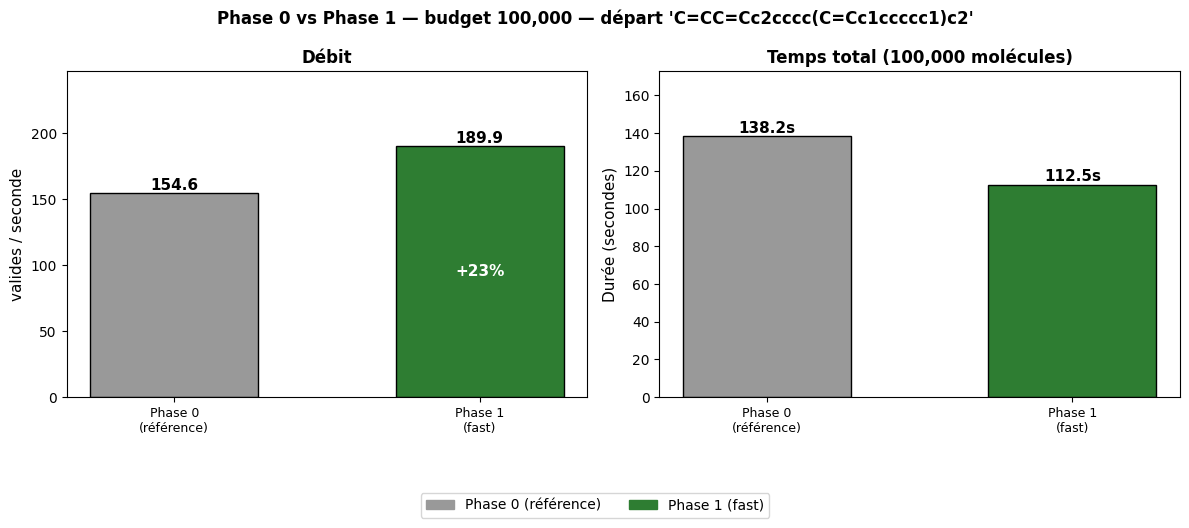

In [8]:
import time
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

P1_BENCH_START  = "C=CC=Cc2cccc(C=Cc1ccccc1)c2"
P1_BENCH_ATOMS  = 40
P1_BENCH_BUDGET = 100000    # augmenter à 50000 pour les chiffres headline

CONFIGS_P1 = [
    {
        "label":  "Phase 0\n(référence)",
        "color":  "#999999",
        "fn":     "budget_bfs",
    },
    {
        "label":  "Phase 1\n(fast)",
        "color":  "#2e7d32",
        "fn":     "budget_bfs_fast",
    },
]

_fn_map = {"budget_bfs": budget_bfs, "budget_bfs_fast": budget_bfs_fast}

p1_setup(P1_BENCH_ATOMS)
bench_filters_p1 = [HuckelCompatible()] + dp.setup_filters("chembl_zinc")

def run_p1(cfg):
    lbl = cfg["label"].replace("\n", " ")
    print(f"  [{lbl}]")
    t0 = time.time()
    r  = _fn_map[cfg["fn"]](P1_BENCH_START, bench_filters_p1, P1_BENCH_BUDGET)
    elapsed = time.time() - t0
    r["elapsed"]   = elapsed
    r["valides_s"] = r["n_valid"] / elapsed
    print(f"    → {r['n_valid']:,} valides / {r['n_invalid']:,} invalides  "
          f"{elapsed:.1f}s  {r['valides_s']:.1f} v/s")
    return r

print("=" * 70)
print(f"PHASE 0 vs PHASE 1 — budget {P1_BENCH_BUDGET:,} — départ '{P1_BENCH_START}'")
print("=" * 70 + "\n")

results_p1 = [run_p1(cfg) for cfg in CONFIGS_P1]

# ── Vérification d'équivalence ────────────────────────────────────────────────
r_ref, r_fast = results_p1[0], results_p1[1]
print()
if all(r_ref[k] == r_fast[k] for k in ("n_valid", "n_invalid", "seen")):
    print(f"  ✅ comptes IDENTIQUES — accélération ×{r_ref['elapsed'] / r_fast['elapsed']:.2f}")
else:
    print(f"  ❌ comptes DIFFÉRENTS : {r_ref} != {r_fast}")

# ── Tableau récapitulatif ─────────────────────────────────────────────────────
ref_s = results_p1[0]["valides_s"]
print()
print("=" * 70)
print(f"{'Config':<24} {'valides/s':>10}  {'vs Phase 0':>10}  {'valides':>8}  {'durée':>7}")
print("=" * 70)
for cfg, r in zip(CONFIGS_P1, results_p1):
    lbl  = cfg["label"].replace("\n", " ")
    gain = (r["valides_s"] / ref_s - 1) * 100
    mark = " ✅" if gain > 0 else ""
    print(f"{lbl:<24} {r['valides_s']:>10.1f}  {gain:>+9.0f}%  {r['n_valid']:>8,}  {r['elapsed']:>6.1f}s{mark}")
print("=" * 70)

# ── Graphique ─────────────────────────────────────────────────────────────────
labels = [c["label"] for c in CONFIGS_P1]
colors = [c["color"]  for c in CONFIGS_P1]
vals_s = [r["valides_s"] for r in results_p1]
times  = [r["elapsed"]   for r in results_p1]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
x = np.arange(len(CONFIGS_P1))

# Panneau 1 : débit valides/s
bars0 = axes[0].bar(x, vals_s, color=colors, edgecolor="black", width=0.55)
for b, v in zip(bars0, vals_s):
    axes[0].text(b.get_x()+b.get_width()/2, b.get_height()+0.3,
                 f"{v:.1f}", ha="center", va="bottom", fontsize=11, fontweight="bold")
for i, v in enumerate(vals_s):
    g = (v / ref_s - 1) * 100
    if i > 0:
        axes[0].text(x[i], v/2, f"{g:+.0f}%", ha="center", va="center",
                     fontsize=11, color="white", fontweight="bold")
axes[0].set_xticks(x); axes[0].set_xticklabels(labels, fontsize=9)
axes[0].set_ylabel("valides / seconde", fontsize=11)
axes[0].set_title("Débit", fontsize=12, fontweight="bold")
axes[0].set_ylim(0, max(vals_s)*1.3)

# Panneau 2 : durée
bars1 = axes[1].bar(x, times, color=colors, edgecolor="black", width=0.55)
for b, v in zip(bars1, times):
    axes[1].text(b.get_x()+b.get_width()/2, b.get_height()+0.3,
                 f"{v:.1f}s", ha="center", va="bottom", fontsize=11, fontweight="bold")
axes[1].set_xticks(x); axes[1].set_xticklabels(labels, fontsize=9)
axes[1].set_ylabel("Durée (secondes)", fontsize=11)
axes[1].set_title(f"Temps total ({P1_BENCH_BUDGET:,} molécules)", fontsize=12, fontweight="bold")
axes[1].set_ylim(0, max(times)*1.25)

patches = [mpatches.Patch(color=c["color"], label=c["label"].replace("\n", " "))
           for c in CONFIGS_P1]
fig.legend(handles=patches, loc="lower center", bbox_to_anchor=(0.5, -0.05),
           ncol=2, fontsize=10)
plt.suptitle(f"Phase 0 vs Phase 1 — budget {P1_BENCH_BUDGET:,} — départ '{P1_BENCH_START}'",
             fontsize=12, fontweight="bold")
plt.tight_layout(rect=[0, 0.1, 1, 1])
plt.show()


## Test B — Profilage : où part le temps ?

`cProfile` sur un run borné à **`BENCH_BUDGET` molécules**, config de production corrigée (espace pruné + filtres Huckel → ChEMBL/ZINC → Hetero).

Réduire `BENCH_BUDGET` pour un run plus court (2 000 → ~5 s) ; 50 000 donne les chiffres headline (~50 s avec surcoût cProfile).


In [ ]:
import cProfile, pstats, io, json, os, subprocess, sys, tempfile

BENCH_BUDGET  = 10000    # augmenter à 50000 pour les chiffres headline (~50s)
BENCH_ATOMS   = 40
BENCH_START   = "C=CC=Cc2cccc(C=Cc1ccccc1)c2"

# Config de production corrigée (configure aussi l'état global pour les cellules suivantes)
dp.setup_default_parameters(accepted_atoms=["C","N","O","S","F","Cl","Br"], max_heavy_atoms=BENCH_ATOMS)
dp.setup_default_action_space()
MolecularGraph.action_space = [a for a in MolecularGraph.action_space if a is not mg.InsertCarbonMG]
mg.ChangeBondMG.avoid_bond_breaking = False
mg.AddAtomMG.avoid_sp3_on_sp3 = True

from evomol.search.enumeration import budget_bfs_fast
bench_filters = [HuckelCompatible()] + dp.setup_filters("chembl_zinc")

print(f"Profilage (fast) : budget={BENCH_BUDGET:,}  start={BENCH_START!r}  max_atoms={BENCH_ATOMS}")
print(f"Filtres          : {[f.name for f in bench_filters]}")

# Profiling dans un sous-process isolé : évite les hooks ipykernel/debugpy
# qui appellent sys.setprofile() et empêchent cProfile.enable() dans le kernel.
_PROF_SCRIPT = """
import sys, json, os, cProfile
cwd, prof_file = sys.argv[1], sys.argv[2]
os.chdir(cwd); sys.path[:0] = [cwd]
cfg = json.loads(sys.stdin.read())
from rdkit import RDLogger; RDLogger.DisableLog("rdApp.*")
from evomol import default_parameters as dp
from evomol.action import molecular_graph as mg
from evomol.evaluation.huckel import HuckelCompatible
from evomol.representation import MolecularGraph
from evomol.search.enumeration import budget_bfs_fast
dp.setup_default_parameters(accepted_atoms=cfg["atoms"], max_heavy_atoms=cfg["max_atoms"])
dp.setup_default_action_space()
MolecularGraph.action_space = [a for a in MolecularGraph.action_space if a is not mg.InsertCarbonMG]
mg.ChangeBondMG.avoid_bond_breaking = False
mg.AddAtomMG.avoid_sp3_on_sp3 = True
bench_filters = [HuckelCompatible()] + dp.setup_filters("chembl_zinc")
pr = cProfile.Profile()
pr.enable()
result = budget_bfs_fast(cfg["start"], bench_filters, cfg["budget"])
pr.disable()
pr.dump_stats(prof_file)
print(json.dumps(result))
"""

_prof_file = tempfile.mktemp(suffix=".prof")
_cfg = json.dumps({"start": BENCH_START, "budget": BENCH_BUDGET,
                   "atoms": ["C","N","O","S","F","Cl","Br"], "max_atoms": BENCH_ATOMS})
_proc = subprocess.run(
    [sys.executable, "-c", _PROF_SCRIPT, os.getcwd(), _prof_file],
    input=_cfg, capture_output=True, text=True,
)
if _proc.returncode != 0:
    raise RuntimeError(f"Profiling subprocess failed:\n{_proc.stderr}")

result = json.loads(_proc.stdout.strip())
print(f"\nRésultat : {result['n_valid']:,} valides / {result['n_invalid']:,} invalides / {result['seen']:,} vus")
print()

# Synthèse hotspots
import os as _os
stats = pstats.Stats(_prof_file, stream=io.StringIO())
total_tt = sum(v[2] for v in stats.stats.values())

HOTSPOTS = [
    ("update_representation (recalcul graphe)",     lambda f,n: n == "update_representation"),
    ("MolecularGraph __init__/__copy__/canonical",  lambda f,n: f.endswith("molecular_graph.py")),
    ("RDKit itération atomes/liaisons (wrappers)",  lambda f,n: "rdkit" in f and "Chem" in f),
    ("RDKit Kekulize",                              lambda f,n: "ekulize" in n),
    ("Filtre Huckel",                               lambda f,n: f.endswith("huckel.py")),
    ("Filtre ECFP / GCF (ChEMBL-ZINC)",            lambda f,n: "unknown_ecfp" in f or "generic_cyclic" in f),
    ("Expansion voisins (action/enumeration)",      lambda f,n: f.endswith("enumeration.py") or f"{_os.sep}action{_os.sep}" in f),
    ("Molecule.__init__ / evaluation",              lambda f,n: f.endswith("molecule.py") or f.endswith("evaluation.py")),
]

buckets = {lbl: [0.0, 0] for lbl, _ in HOTSPOTS}
for (fn, _ln, funcname), (_cc, nc, tt, _ct, _cal) in stats.stats.items():
    for lbl, pred in HOTSPOTS:
        try:
            if pred(fn, funcname):
                buckets[lbl][0] += tt; buckets[lbl][1] += nc; break
        except Exception: pass

print(f"{'HOTSPOT':<46} {'tottime':>8} {'%':>6}  {'appels':>12}")
print("-" * 78)
accounted = 0.0
for lbl, _ in HOTSPOTS:
    tt, nc = buckets[lbl]
    accounted += tt
    pct = 100*tt/total_tt if total_tt else 0
    star = " ◀" if pct > 15 else ""
    print(f"{lbl:<46} {tt:>8.2f} {pct:>5.1f}%  {nc:>12,}{star}")
print("-" * 78)
other = total_tt - accounted
print(f"{'(autre / overhead Python)':<46} {other:>8.2f} {100*other/total_tt:>5.1f}%")
print(f"{'TOTAL':>46} {total_tt:>8.2f}")
if result['seen']:
    print(f"\n→ {1e6*total_tt/result['seen']:.0f} µs/molécule (avec surcoût cProfile)")


Profilage (fast) : budget=10,000  start='C=CC=Cc2cccc(C=Cc1ccccc1)c2'  max_atoms=40
Filtres          : ['huckel_compatible', 'UnknownGCF_chembl_zinc', 'FilterUnknownGCF', 'UnknownECFP_chembl_zinc', 'FilterUnknownECFP']

Résultat : 3,595 valides / 6,634 invalides / 10,229 vus

HOTSPOT                                         tottime      %        appels
------------------------------------------------------------------------------
update_representation (recalcul graphe)            1.64  10.8%        55,687
MolecularGraph __init__/__copy__/canonical         3.92  26.0%       381,572 ◀
RDKit itération atomes/liaisons (wrappers)         3.76  24.9%    10,745,387 ◀
RDKit Kekulize                                     0.00   0.0%             0
Filtre Huckel                                      0.55   3.7%       400,692
Filtre ECFP / GCF (ChEMBL-ZINC)                    1.06   7.0%        81,093
Expansion voisins (action/enumeration)             0.03   0.2%        42,411
Molecule.__init__ / eval